# 05 — Redes recurrentes: LSTM y DRNN (familia A: dominio del tiempo)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/garcialvarez/HAR/blob/main/05_recurrentes_lstm.ipynb)

**Entrega 2 — Notebook 5 de 7.** Segunda arquitectura en el dominio del tiempo: redes **recurrentes** con
celdas LSTM, que procesan la ventana paso a paso y mantienen un estado interno. Es la familia del
artículo de referencia (Murad & Pyun, 2017), cuyo mejor resultado sobre este dataset es una **DRNN
unidireccional de 4 capas con 96.7 %**.

**Experimentos (iteraciones):**

| Id | Arquitectura | Idea |
|---|---|---|
| R1 | LSTM de 2 capas (64 unidades) | recurrente mínima |
| R2 | DRNN: LSTM de 4 capas (64 unidades) | la arquitectura del artículo |
| R3 | BiLSTM de 2 capas (64 unidades) | leer la ventana en ambos sentidos |
| R4 | CNN-LSTM: 2 × Conv1D + MaxPool(2) → LSTM(64) | la convolución resume y acorta la secuencia (64 pasos) |

**Entrada:** los 9 canales crudos, como en el artículo (sin magnitudes ni velocidad: en el notebook 04 no
aportaron una mejora distinguible del ruido). **Protocolo** idéntico al notebook 04: validación por sujeto
dentro del train, normalizador ajustado solo con entrenamiento, test oficial al final, y media ± desviación
sobre varias semillas (aquí (42, 43), por el costo de entrenar redes recurrentes en CPU).

> **Tiempo de ejecución.** Las LSTM son lentas en CPU. En Colab, activa una **GPU**
> (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*) para que el notebook tarde pocos minutos.

In [1]:
# --- Arranque (Colab o local): clona el repositorio si hace falta y entra en él ---
import os, subprocess

REPO_URL = "https://github.com/garcialvarez/HAR.git"

if not os.path.exists("src/data_loader.py"):      # en Colab: cwd = /content
    if not os.path.isdir("HAR"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("HAR")

print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: C:\Users\GARCIA\Documents\HAR


In [2]:
# Instala las dependencias (en Colab casi todas ya vienen instaladas).
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


C:\Users\GARCIA\Documents\HAR\.venv\Scripts\python.exe: No module named pip


In [3]:
# Descarga y descomprime el UCI HAR Dataset (si no está ya en data/raw/).
import sys
sys.path.append("src")

from data_loader import download_dataset
download_dataset()

WindowsPath('C:/Users/GARCIA/Documents/HAR/data/raw/UCI_HAR_Dataset')

In [4]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from data_loader import load_raw_signals
from evaluation import plot_confusion_matrix, plot_history
from preprocessing import CLASS_NAMES, encode_labels
from training import evaluate_keras, fit_keras, prepare_time_inputs

pd.set_option("display.width", 130)
SEEDS = (42, 43)
MAX_EPOCHS = 30

X_tr_raw, y_tr_s, s_tr = load_raw_signals("train")
X_te_raw, y_te_s, _ = load_raw_signals("test")
y_tr, y_te = encode_labels(y_tr_s), encode_labels(y_te_s)
s_tr = s_tr.values

d = prepare_time_inputs(X_tr_raw, X_te_raw, s_tr, "raw")       # 9 canales, partición por sujeto
ytr, yva = y_tr[d["tr"]], y_tr[d["va"]]
print("entrenamiento:", d["Xtr"].shape, "| validación:", d["Xva"].shape, "| test:", d["Xte"].shape,
      "| GPU:", bool(tf.config.list_physical_devices("GPU")))

entrenamiento: (5551, 128, 9) | validación: (1801, 128, 9) | test: (2947, 128, 9) | GPU: False


## 1. Arquitecturas

Una LSTM lee la ventana de 128 pasos en orden; en cada paso decide qué recordar y qué olvidar. Las capas
intermedias devuelven la secuencia completa (`return_sequences=True`) para que la siguiente capa la procese;
la última devuelve solo su estado final, que alimenta al clasificador.

In [5]:
def build_lstm(input_shape, n_layers=2, units=64, bidirectional=False, name="lstm"):
    inp = keras.Input(input_shape)
    x = inp
    for k in range(n_layers):
        capa = layers.LSTM(units, return_sequences=(k < n_layers - 1))
        x = layers.Bidirectional(capa)(x) if bidirectional else capa(x)
        x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(6, activation="softmax")(x), name=name)


def build_cnn_lstm(input_shape, units=64, name="cnn_lstm"):
    inp = keras.Input(input_shape)
    x = inp
    for _ in range(2):
        x = layers.Conv1D(64, 5, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling1D(2)(x)                      # 128 -> 64 pasos
    x = layers.Dropout(0.3)(x)
    x = layers.LSTM(units)(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(6, activation="softmax")(x), name=name)


ARQUITECTURAS = {
    "R1": ("LSTM 2 capas", lambda s: build_lstm(s, 2, name="r1_lstm2")),
    "R2": ("DRNN: LSTM 4 capas", lambda s: build_lstm(s, 4, name="r2_drnn4")),
    "R3": ("BiLSTM 2 capas", lambda s: build_lstm(s, 2, bidirectional=True, name="r3_bilstm2")),
    "R4": ("CNN-LSTM", lambda s: build_cnn_lstm(s, name="r4_cnn_lstm")),
}
for k, (nombre, f) in ARQUITECTURAS.items():
    print(f"{k} {nombre:20s} parámetros: {f(d['Xtr'].shape[1:]).count_params():,}")

R1 LSTM 2 capas         parámetros: 56,518
R2 DRNN: LSTM 4 capas   parámetros: 122,566
R3 BiLSTM 2 capas       parámetros: 145,350


R4 CNN-LSTM             parámetros: 61,574


## 2. Entrenamiento

Mismo procedimiento que en el notebook 04: Adam (lr = 1e-3), `EarlyStopping` sobre la pérdida de
validación (paciencia 8, restaura los mejores pesos) y `ReduceLROnPlateau`.

In [6]:
runs, histories = {}, {}
t_total = time.perf_counter()

for exp, (nombre, build) in ARQUITECTURAS.items():
    runs[exp] = []
    for seed in SEEDS:
        keras.utils.set_random_seed(seed)
        model = build(d["Xtr"].shape[1:])
        hist, seg = fit_keras(model, d["Xtr"], ytr, d["Xva"], yva, epochs=MAX_EPOCHS)
        mejor = int(np.argmin(hist.history["val_loss"]))
        res = evaluate_keras(f"05_{exp}_s{seed}", "tiempo_recurrente", model, d["Xte"], y_te, CLASS_NAMES, seg,
                             notes=f"{exp}: {nombre}, semilla={seed}")
        res.update(val_loss=hist.history["val_loss"][mejor], val_acc=hist.history["val_accuracy"][mejor],
                   epocas=len(hist.history["loss"]))
        runs[exp].append(res)
        if seed == SEEDS[0]:
            histories[exp] = hist
    print(f"{exp} listo ({(time.perf_counter() - t_total) / 60:.1f} min acumulados)")

[05_R1_s42] accuracy=0.8962  F1 macro=0.8956  latencia=5.66 ms/ventana


[05_R1_s43] accuracy=0.9026  F1 macro=0.9011  latencia=5.59 ms/ventana
R1 listo (3.3 min acumulados)


[05_R2_s42] accuracy=0.8897  F1 macro=0.8847  latencia=12.20 ms/ventana


[05_R2_s43] accuracy=0.8880  F1 macro=0.8881  latencia=12.13 ms/ventana
R2 listo (9.2 min acumulados)


[05_R3_s42] accuracy=0.8836  F1 macro=0.8834  latencia=9.78 ms/ventana


[05_R3_s43] accuracy=0.9091  F1 macro=0.9093  latencia=9.82 ms/ventana
R3 listo (13.6 min acumulados)


[05_R4_s42] accuracy=0.9169  F1 macro=0.9170  latencia=2.11 ms/ventana


[05_R4_s43] accuracy=0.9253  F1 macro=0.9262  latencia=2.09 ms/ventana
R4 listo (15.1 min acumulados)


## 3. Resultados por experimento

,arquitectura,val acc,test acc,F1 macro test,parámetros,latencia (ms/ventana),tamaño (KB),épocas (media),entrenamiento (s)
R1,LSTM 2 capas,0.9725 ± 0.0081,0.8994 ± 0.0032,0.8983 ± 0.0028,56518,5.624,709.0,16.0,95.6
R2,DRNN: LSTM 4 capas,0.9631 ± 0.0108,0.8889 ± 0.0008,0.8864 ± 0.0017,122566,12.165,1504.0,13.0,165.8
R3,BiLSTM 2 capas,0.9864 ± 0.0008,0.8963 ± 0.0127,0.8964 ± 0.0130,145350,9.805,1770.0,12.5,124.3
R4,CNN-LSTM,0.9800 ± 0.0044,0.9211 ± 0.0042,0.9216 ± 0.0046,61574,2.1,787.0,15.0,42.6


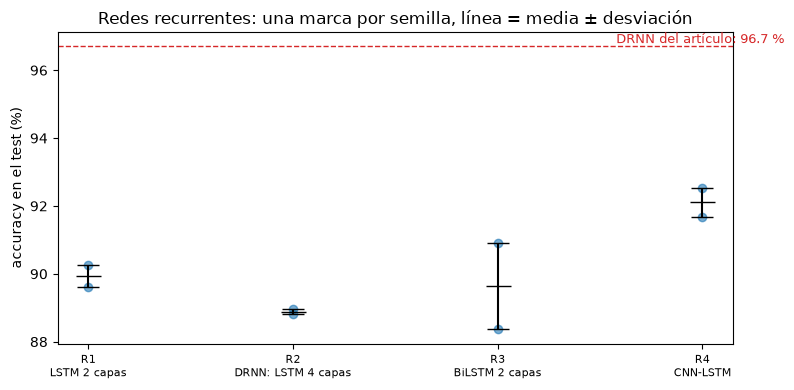

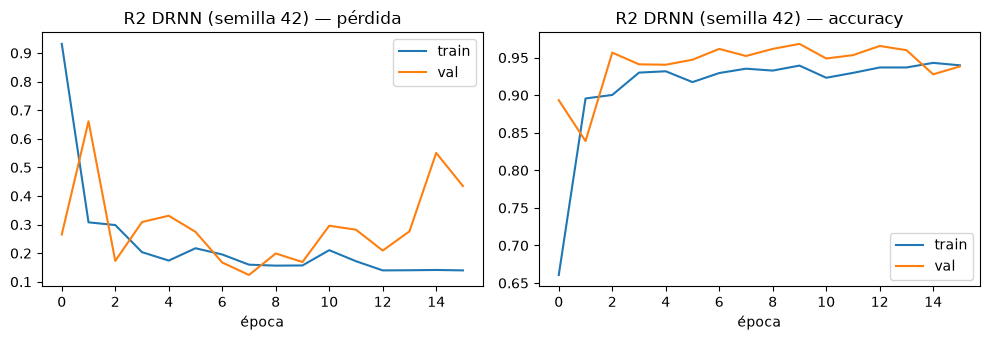

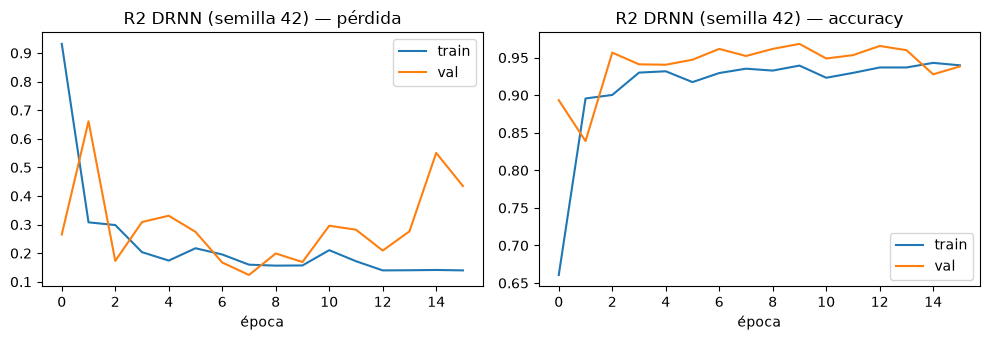

In [7]:
def ms(exp, clave):
    v = np.array([r[clave] for r in runs[exp]], dtype=float)
    return v.mean(), v.std()


filas = {}
for exp, (nombre, _) in ARQUITECTURAS.items():
    fila = {"arquitectura": nombre}
    for etiqueta, clave in [("val acc", "val_acc"), ("test acc", "accuracy"), ("F1 macro test", "f1_macro")]:
        m, s = ms(exp, clave)
        fila[etiqueta] = f"{m:.4f} ± {s:.4f}"
    fila["parámetros"] = runs[exp][0]["n_params"]
    fila["latencia (ms/ventana)"] = round(ms(exp, "latency_single_ms")[0], 3)
    fila["tamaño (KB)"] = round(runs[exp][0]["model_size_kb"], 0)
    fila["épocas (media)"] = round(ms(exp, "epocas")[0], 1)
    fila["entrenamiento (s)"] = round(ms(exp, "train_time_s")[0], 1)
    filas[exp] = fila
display(pd.DataFrame(filas).T)

fig, ax = plt.subplots(figsize=(8, 4))
for k, exp in enumerate(ARQUITECTURAS):
    accs = [100 * r["accuracy"] for r in runs[exp]]
    ax.scatter([k] * len(accs), accs, color="C0", alpha=0.6, zorder=3)
    ax.errorbar(k, np.mean(accs), yerr=np.std(accs), fmt="_", color="k", capsize=8, markersize=18, zorder=4)
ax.axhline(96.7, color="C3", ls="--", lw=1)
ax.text(len(ARQUITECTURAS) - 0.6, 96.8, "DRNN del artículo: 96.7 %", color="C3", ha="right", fontsize=9)
ax.set_xticks(range(len(ARQUITECTURAS)), [f"{e}\n{ARQUITECTURAS[e][0]}" for e in ARQUITECTURAS], fontsize=8)
ax.set_ylabel("accuracy en el test (%)")
ax.set_title("Redes recurrentes: una marca por semilla, línea = media ± desviación")
fig.tight_layout()
plt.show()

plot_history(histories["R2"], title="R2 DRNN (semilla 42)", save_name="05_curvas_R2.png")

## 4. Finalista de la familia y errores por clase

Se elige por la **menor pérdida de validación media** (no por el test).

Finalista recurrente: R4 (CNN-LSTM), pérdida de validación media = 0.0784


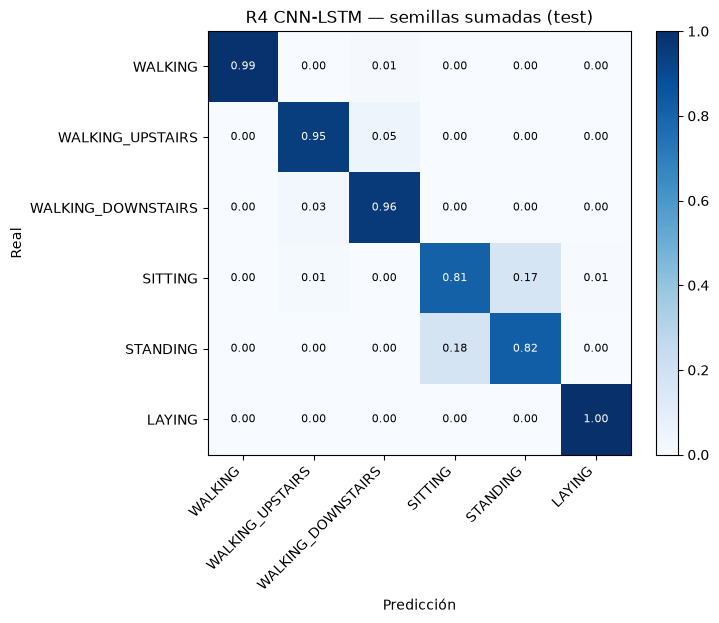

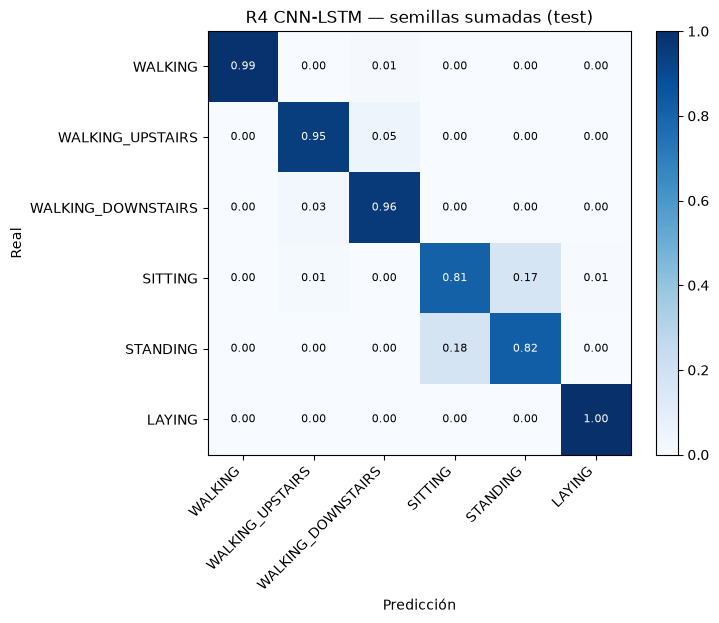

In [8]:
finalista = min(ARQUITECTURAS, key=lambda e: ms(e, "val_loss")[0])
print(f"Finalista recurrente: {finalista} ({ARQUITECTURAS[finalista][0]}), "
      f"pérdida de validación media = {ms(finalista, 'val_loss')[0]:.4f}")

cm = np.sum([r["confusion_matrix"] for r in runs[finalista]], axis=0)
plot_confusion_matrix(cm, CLASS_NAMES, title=f"{finalista} {ARQUITECTURAS[finalista][0]} — semillas sumadas (test)",
                      save_name="05_confusion_finalista.png")

## Conclusiones

In [9]:
mejor_test = max(ARQUITECTURAS, key=lambda e: ms(e, "accuracy")[0])
print(f"- Mejor accuracy media en test: {mejor_test} ({ARQUITECTURAS[mejor_test][0]}) = {100 * ms(mejor_test, 'accuracy')[0]:.2f} %.")
print(f"- DRNN de 4 capas (R2): {100 * ms('R2', 'accuracy')[0]:.2f} % frente al 96.7 % del artículo de referencia.")
lat = {e: ms(e, "latency_single_ms")[0] for e in ARQUITECTURAS}
print("- Latencia (ms/ventana, un hilo): " + ", ".join(f"{e} = {v:.2f}" for e, v in lat.items()))
conf = np.array(cm)
i, j = CLASS_NAMES.index("SITTING"), CLASS_NAMES.index("STANDING")
print(f"- En el finalista, SITTING↔STANDING = {100 * (conf[i, j] + conf[j, i]) / (conf.sum() - np.trace(conf)):.0f} % de los errores.")

- Mejor accuracy media en test: R4 (CNN-LSTM) = 92.11 %.
- DRNN de 4 capas (R2): 88.89 % frente al 96.7 % del artículo de referencia.
- Latencia (ms/ventana, un hilo): R1 = 5.62, R2 = 12.17, R3 = 9.80, R4 = 2.10
- En el finalista, SITTING↔STANDING = 77 % de los errores.


**Lectura de los resultados.**

- **La mejor recurrente es R4 (CNN-LSTM).** Las dos convoluciones iniciales resumen la señal y acortan la
  secuencia a 64 pasos: la red es más precisa y bastante más rápida que las LSTM "puras".
- **Más capas (R2) o leer en ambos sentidos (R3) no ayudan:** R1, R2 y R3 quedan en torno al 89–90 %, y
  R2/R3 tienen más parámetros y mayor latencia por ventana que R1.
- **Brecha con el artículo.** La DRNN de 4 capas (R2) no reproduce el 96.7 % publicado por Murad & Pyun
  (2017): aquí obtiene ≈ 89 %. No comprobamos la causa. Nuestro protocolo es estricto (parada temprana sobre
  sujetos de validación no vistos, sin ajustar hiperparámetros con el test) y no hicimos búsqueda de
  hiperparámetros para las recurrentes; diferencias de protocolo o de ajuste respecto al artículo podrían
  explicarlo, pero es una hipótesis, no un resultado.
- **Generalización:** todas las recurrentes llegan a ≈ 96–99 % en los sujetos de validación y bajan 5–9
  puntos en los del test: el cuello de botella vuelve a ser el cambio de sujeto.

Siguiente: [`06_cnn2d_tiempo_frecuencia.ipynb`](06_cnn2d_tiempo_frecuencia.ipynb) — la segunda familia:
CNN 2D sobre espectrogramas (modalidad tiempo-frecuencia).